# Phase 3: RL Environment

### Objective
Demonstrate the Gymnasium environment.

### Note on Pending Integrations (Phase 6+)
This environment prototype correctly manages state transitions, step tracking, valid RDKit edits, and rewards. However, the final integration of the PyTorch Geometric / GNN-based graph state along with scalar properties directly into the observation space is pending and belongs to the next stage (Phase 6: GNN Encoder). Currently, the observation space only surfaces the scalar properties (QED, SAS, step, similarity) to test the transition loop.

In [1]:
import torch
import sys
import os
sys.path.append(os.path.abspath(".."))
from implementation.environment import MolecularEnvironment
from rdkit.Chem import Draw

Initial state (Scalars only pending Phase 6): {'qed': array([0.44262838], dtype=float32), 'sas': array([1.], dtype=float32), 'similarity': array([1.], dtype=float32), 'step': array([0.], dtype=float32)}


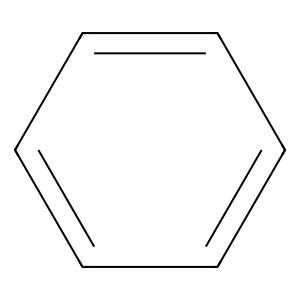

In [2]:
env = MolecularEnvironment()
obs, info = env.reset(options={"starting_smiles": "c1ccccc1"})
print("Initial state (Scalars only pending Phase 6):", obs)
Draw.MolToImage(env.current_mol)

Next state (Scalars): {'qed': array([0.45880628], dtype=float32), 'sas': array([1.], dtype=float32), 'similarity': array([0.27272728], dtype=float32), 'step': array([0.05], dtype=float32)}
Reward: -1.2665493649690924


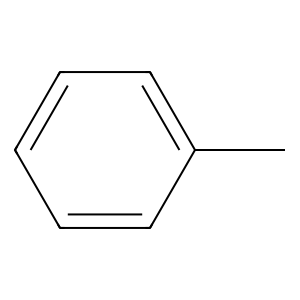

In [3]:
# Take a step (Add atom Carbon to atom index 0)
action = {"type": 0, "atom1": 0, "atom2": 0, "element": 0, "bond_delta": 1}
obs, reward, done, _, info = env.step(action)
print("Next state (Scalars):", obs)
print("Reward:", reward)
Draw.MolToImage(env.current_mol)